# Hodgkin-Huxley model

Imitating Hodgkin-Huxley model and performing some experiments on it to get a better view on it.

In [89]:
import math
import numpy as np
import ipywidgets as widgets
import matplotlib.pyplot as plt

from typing import Callable, Tuple
from tqdm import tqdm
from dataclasses import dataclass, replace
from pathlib import Path

# Initiating the environment

State standard constants of the Hodgkin-Huxley neuron

In [90]:
# Parameters 
@dataclass(frozen=True)
class Constants:
    Cm: float = 1.0          # µF/cm^2
    gNa: float = 120.0       # mS/cm^2
    gK:  float = 36.0        # mS/cm^2
    gL:  float = 0.3         # mS/cm^2
    ENa: float = 50.0        # mV
    EK:  float = -77.0       # mV
    EL:  float = -54.387     # mV

params = Constants()

Helper functions (numerical stability)

In [91]:
def _lim_ratio(x, k, limit):
    """
    Stable evaluation of:
        x / (1 - exp(-x/k))
    near x=0 (avoids 0/0 and cancellation errors).

    'limit' is the known limit value as x -> 0.
    """
    x = _arr(x)
    y = x / k
    out = np.empty_like(y)

    mask = np.abs(y) < 1e-6
    out[mask] = float(limit)

    den = -np.expm1(-y[~mask])  # 1 - exp(-y) computed stably
    out[~mask] = x[~mask] / den
    return out
def _arr(x):
    """Ensure numpy array format"""
    return np.asarray(x, dtype=float)


Gating rate functions for activation/inactivation

In [92]:
def alpha_m(V):
    V = _arr(V)
    return 0.1 * _lim_ratio(V + 40.0, 10.0, 10.0)

def beta_m(V):
    V = _arr(V)
    return 4.0 * np.exp(-(V + 65.0) / 18.0)

def alpha_h(V):
    V = _arr(V)
    return 0.07 * np.exp(-(V + 65.0) / 20.0)

def beta_h(V):
    V = _arr(V)
    return 1.0 / (1.0 + np.exp(-(V + 35.0) / 10.0))

def alpha_n(V):
    V = _arr(V)
    return 0.01 * _lim_ratio(V + 55.0, 10.0, 10.0)

def beta_n(V):
    V = _arr(V)
    return 0.125 * np.exp(-(V + 65.0) / 80.0)


Gate steady-state function and time constants

In [93]:
def gate_inf_tau(V):
    """
    Outputs:
      x_inf: dict {m,h,n} steady-state values at voltage V
      tau_x: dict {m,h,n} time constants (ms) at voltage V
    """
    am, bm = alpha_m(V), beta_m(V)
    ah, bh = alpha_h(V), beta_h(V)
    an, bn = alpha_n(V), beta_n(V)

    m_tau = 1.0 / (am + bm)
    h_tau = 1.0 / (ah + bh)
    n_tau = 1.0 / (an + bn)

    m_inf = am * m_tau
    h_inf = ah * h_tau
    n_inf = an * n_tau

    return {"m": m_inf, "h": h_inf, "n": n_inf}, {"m": m_tau, "h": h_tau, "n": n_tau}

In [94]:
def ionic_currents(V, m, h, n, p=params):
    """
    Output is (INa, IK, IL) in µA/cm^2
    """
    gNa_t = p.gNa * (m**3) * h
    gK_t  = p.gK  * (n**4)
    INa = gNa_t * (V - p.ENa)
    IK  = gK_t  * (V - p.EK)
    IL  = p.gL  * (V - p.EL)
    return INa, IK, IL

def step_current(t, amp=10.0, t_on=10.0, t_off=40.0):
    """Square step current (µA/cm^2)"""
    return amp if (t_on <= t < t_off) else 0.0

Current clamp (main one for spiking, F–I, strength–duration, dt sensitivity)

In [95]:
def simulate_current_clamp(T=50.0, dt=0.01, V0=-65.0, I_of_t=None, p=params):
    """
    Simulate HH under current clamp:
        Cm dV/dt = I_ext(t) - (INa + IK + IL)

    Returns a dict with time series:
        t, V, m, h, n, INa, IK, IL, Iext
    """
    if I_of_t is None:
        I_of_t = lambda t: 0.0

    steps = int(np.round(T / dt)) + 1
    t = np.arange(steps) * dt

    V = np.empty(steps)
    m = np.empty(steps)
    h = np.empty(steps)
    n = np.empty(steps)

    INa_arr = np.empty(steps)
    IK_arr  = np.empty(steps)
    IL_arr  = np.empty(steps)
    Iext_arr = np.empty(steps)

    x_inf0, _ = gate_inf_tau(V0)
    V[0] = V0
    m[0] = float(x_inf0["m"])
    h[0] = float(x_inf0["h"])
    n[0] = float(x_inf0["n"])

    for k in range(steps - 1):
        Iext = float(I_of_t(t[k]))
        Iext_arr[k] = Iext

        x_inf, tau_x = gate_inf_tau(V[k])
        dmdt = (x_inf["m"] - m[k]) / tau_x["m"]
        dhdt = (x_inf["h"] - h[k]) / tau_x["h"]
        dndt = (x_inf["n"] - n[k]) / tau_x["n"]

        INa, IK, IL = ionic_currents(V[k], m[k], h[k], n[k], p)
        dVdt = (Iext - (INa + IK + IL)) / p.Cm

        V[k+1] = V[k] + dt * dVdt
        m[k+1] = np.clip(m[k] + dt * dmdt, 0.0, 1.0)
        h[k+1] = np.clip(h[k] + dt * dhdt, 0.0, 1.0)
        n[k+1] = np.clip(n[k] + dt * dndt, 0.0, 1.0)

        INa_arr[k], IK_arr[k], IL_arr[k] = INa, IK, IL

    Iext_arr[-1] = float(I_of_t(t[-1]))
    INa_arr[-1], IK_arr[-1], IL_arr[-1] = ionic_currents(V[-1], m[-1], h[-1], n[-1], p)

    return {
        "t": t, "V": V, "m": m, "h": h, "n": n,
        "INa": INa_arr, "IK": IK_arr, "IL": IL_arr,
        "Iext": Iext_arr
    }

Voltage clamp

In [96]:
def simulate_voltage_clamp(T=50.0, dt=0.01, V_hold=-65.0, Vcmd_of_t=None, p=params):
    """
    Simulate HH under voltage clamp:
      - V is forced to follow Vcmd(t).
      - m,h,n evolve according to the forced V.
      - Returns ionic currents.

    Outputs:
        t, Vcmd, m, h, n, INa, IK, IL
    """
    if Vcmd_of_t is None:
        Vcmd_of_t = lambda t: V_hold

    steps = int(np.round(T / dt)) + 1
    t = np.arange(steps) * dt

    Vcmd = np.empty(steps)
    m = np.empty(steps)
    h = np.empty(steps)
    n = np.empty(steps)

    INa_arr = np.empty(steps)
    IK_arr  = np.empty(steps)
    IL_arr  = np.empty(steps)

    x_inf0, _ = gate_inf_tau(V_hold)
    m[0] = float(x_inf0["m"])
    h[0] = float(x_inf0["h"])
    n[0] = float(x_inf0["n"])

    Vcmd[0] = float(Vcmd_of_t(t[0]))

    for k in range(steps - 1):
        V = float(Vcmd_of_t(t[k]))
        Vcmd[k] = V

        x_inf, tau_x = gate_inf_tau(V)
        dmdt = (x_inf["m"] - m[k]) / tau_x["m"]
        dhdt = (x_inf["h"] - h[k]) / tau_x["h"]
        dndt = (x_inf["n"] - n[k]) / tau_x["n"]

        m[k+1] = np.clip(m[k] + dt * dmdt, 0.0, 1.0)
        h[k+1] = np.clip(h[k] + dt * dhdt, 0.0, 1.0)
        n[k+1] = np.clip(n[k] + dt * dndt, 0.0, 1.0)

        INa, IK, IL = ionic_currents(V, m[k], h[k], n[k], p)
        INa_arr[k], IK_arr[k], IL_arr[k] = INa, IK, IL

    V_last = float(Vcmd_of_t(t[-1]))
    Vcmd[-1] = V_last
    INa_arr[-1], IK_arr[-1], IL_arr[-1] = ionic_currents(V_last, m[-1], h[-1], n[-1], p)

    return {"t": t, "Vcmd": Vcmd, "m": m, "h": h, "n": n, "INa": INa_arr, "IK": IK_arr, "IL": IL_arr}


 Gating kinetics curves: x_inf(V) and tau(V)

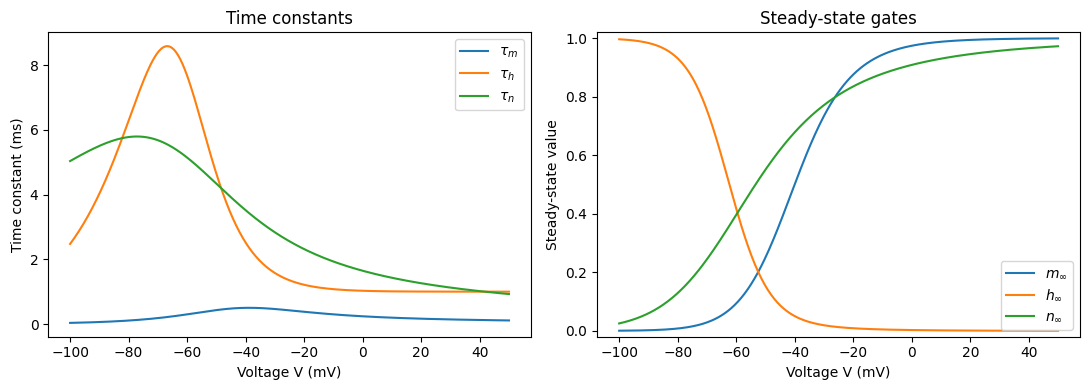

In [97]:
# Voltage range 
Vs = np.linspace(-100.0, 50.0, 400)

# Compute steady-state values and time constants
x_inf, tau_x = gate_inf_tau(Vs)

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Time constants
ax[0].plot(Vs, tau_x["m"], label=r"$\tau_m$")
ax[0].plot(Vs, tau_x["h"], label=r"$\tau_h$")
ax[0].plot(Vs, tau_x["n"], label=r"$\tau_n$")
ax[0].set_xlabel("Voltage V (mV)")
ax[0].set_ylabel("Time constant (ms)")
ax[0].set_title("Time constants")
ax[0].legend()
# Steady-state gating curves
ax[1].plot(Vs, x_inf["m"], label=r"$m_\infty$")
ax[1].plot(Vs, x_inf["h"], label=r"$h_\infty$")
ax[1].plot(Vs, x_inf["n"], label=r"$n_\infty$")
ax[1].set_xlabel("Voltage V (mV)")
ax[1].set_ylabel("Steady-state value")
ax[1].set_title("Steady-state gates")
ax[1].set_ylim(-0.02, 1.02)
ax[1].legend()

plt.tight_layout()
plt.show()


Time constants plot:

    Fast 𝑚: Na activation responds quickly, so it explains the sharp upstroke.
    Slower 𝑛: K activation responds more slowly, it explains delayed repolarization and AHP.

Steady-state gates:

    m = sodium activation gate
    h = sodium inactivation gate
    n = potassium activation gate
    𝑚∞(𝑉) (blue): near 0 at very negative voltages, rises steeply as voltage increases, approaches ~1 at depolarized voltages.
    ℎ∞(𝑉) (orange): near 1 at very negative voltages, falls steeply with depolarization, approaches ~0 at higher voltages.
    𝑛∞(𝑉) (green): increases with voltage (slower/less steep than 𝑚∞), approaches ~1 at high voltages.

Check gating variables at rest

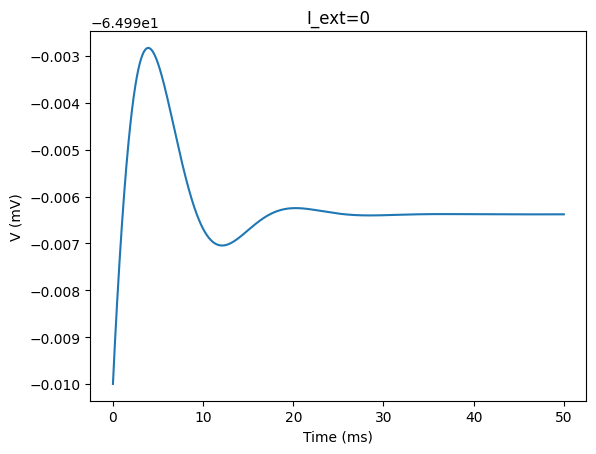

In [98]:
# no input current, so membrane stays near rest
res0 = simulate_current_clamp(T=50.0, dt=0.01, V0=-65.0, I_of_t=lambda t: 0.0, p=params)
plt.plot(res0["t"], res0["V"]); plt.xlabel("Time (ms)"); plt.ylabel("V (mV)"); plt.title("I_ext=0")
plt.show()

The plot demonstrates deviations around ≈ −65 mV

# Experiments

We will look at Hodgkin-Huxley model from different sides, by runnning the experimetns:
1. Current clamp
2. Firing rate vs DC current
3. Strength–duration curve
4. Voltage-clamp validation of gating kinetics 
5. dt sensitivity check

### Current clamp

This section is:

1. to demonstrate that the model can produce a single action potential to a brief input

2. to demonstrate sustained firing to a longer DC step, and to extract simple quantitative measures that will be reused later in the F–I experiment.

In [99]:
# Stimulus protocols for a short square and a long square steps
def brief_pulse_I(amp=10.0, t_on=10.0, width=1.0):
    """Single brief pulse (µA/cm²)."""
    t_off = t_on + width
    return lambda t: step_current(t, amp=amp, t_on=t_on, t_off=t_off)

def long_step_I(amp=10.0, t_on=10.0, t_off=110.0):
    """Long step current (µA/cm²)."""
    return lambda t: step_current(t, amp=amp, t_on=t_on, t_off=t_off)

# Spike detection
def detect_spikes(t, V, thresh=0.0, refractory_ms=2.0):
    """
    Spike times from upward crossings of V = thresh (mV)
    """
    t = np.asarray(t)
    V = np.asarray(V)

    dt = float(t[1] - t[0])
    ref_steps = int(np.round(refractory_ms / dt))

    spike_times = []
    k = 1
    while k < len(V):
        if V[k-1] < thresh and V[k] >= thresh:
            # linear interpolation for more accurate threshold crossing time
            v0, v1 = V[k-1], V[k]
            t0, t1 = t[k-1], t[k]
            tc = t1 if v1 == v0 else t0 + (thresh - v0) * (t1 - t0) / (v1 - v0)
            spike_times.append(tc)
            k += ref_steps
        else:
            k += 1

    return np.array(spike_times, dtype=float)

In [100]:
# Action potential half-width function
def half_width_ms(t, V, peak_idx, V_baseline):
    """
    Action potential half-width around the peak
    """
    Vpk = float(V[peak_idx])
    half = V_baseline + 0.5 * (Vpk - V_baseline)

    # crossing before peak (upstroke)
    pre_idx = np.where((V[:-1] < half) & (V[1:] >= half) & (np.arange(len(V)-1) < peak_idx))[0]
    # crossing after peak (downstroke)
    post_idx = np.where((V[:-1] >= half) & (V[1:] < half) & (np.arange(len(V)-1) > peak_idx))[0]

    if pre_idx.size == 0 or post_idx.size == 0:
        return np.nan

    iu = pre_idx[-1]
    idn = post_idx[0]

    # linear interpolation
    t_up = t[iu] + (half - V[iu]) * (t[iu+1] - t[iu]) / (V[iu+1] - V[iu] + 1e-12)
    t_dn = t[idn] + (half - V[idn]) * (t[idn+1] - t[idn]) / (V[idn+1] - V[idn] + 1e-12)

    return float(t_dn - t_up)

Experiment A: Brief pulse: single spike

A short current pulse is used to elicit a single action potential. This provides a controlled, minimal demonstration of spike generation and allows quantitative characterization of spike shape.

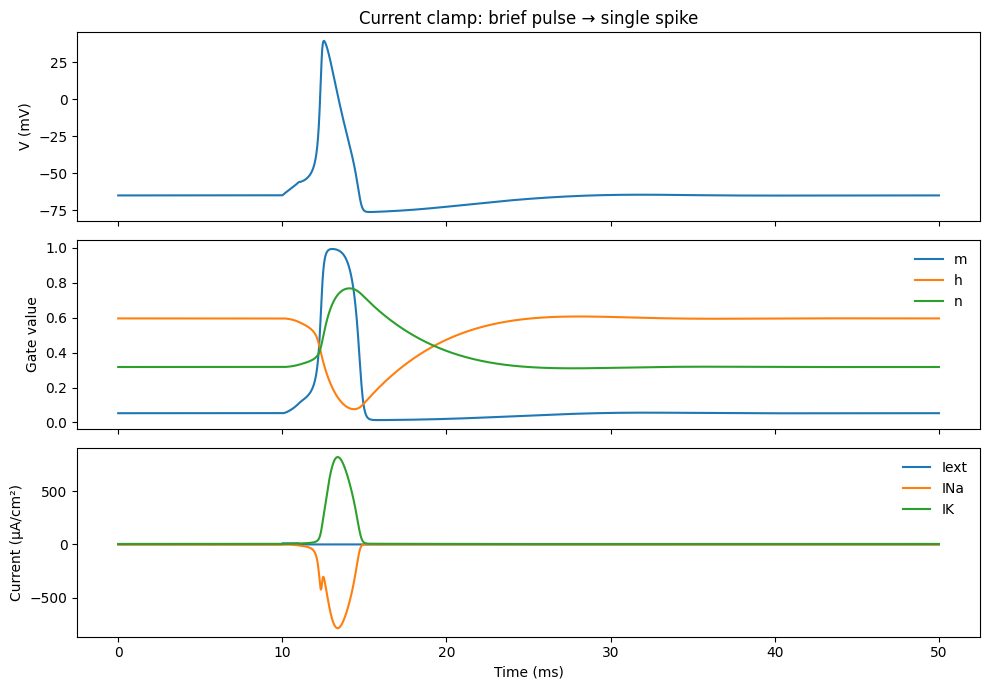

In [101]:
I_pulse = brief_pulse_I(amp=10.0, t_on=10.0, width=1.0)
res_pulse = simulate_current_clamp(T=50.0, dt=0.01, V0=-65.0, I_of_t=I_pulse, p=params)

t = res_pulse["t"]
V = res_pulse["V"]
m = res_pulse["m"]
h = res_pulse["h"]
n = res_pulse["n"]
INa = res_pulse["INa"]
IK  = res_pulse["IK"]
Iext = res_pulse["Iext"]

# Plots: stimulus + voltage, gates, ionic currents
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

ax[0].plot(t, V)
ax[0].set_ylabel("V (mV)")
ax[0].set_title("Current clamp: brief pulse → single spike")

ax[1].plot(t, m, label="m")
ax[1].plot(t, h, label="h")
ax[1].plot(t, n, label="n")
ax[1].set_ylabel("Gate value")
ax[1].legend(frameon=False)

ax[2].plot(t, Iext, label="Iext")
ax[2].plot(t, INa, label="INa")
ax[2].plot(t, IK,  label="IK")
ax[2].set_xlabel("Time (ms)")
ax[2].set_ylabel("Current (µA/cm²)")
ax[2].legend(frameon=False)

plt.tight_layout()
plt.show()

The spike is a HH action potential: a fast upstroke, a repolarizing phase, and a post-spike undershoot due to potassium dominance after the peak:

Before stimulation, the membrane sits at baseline ≈ −65 mV, which is the expected resting level for the standard HH.

Shortly after the pulse onset ~10 ms, we see a rapid depolarization, followed by a spike peak at ~39.3 mV.

The spike is followed by a fast repolarization and an after-hyperpolarization that dips below the baseline  ~−76 mV, then slowly relaxes back toward rest.

In [102]:
# Brief pulse metrics 
pre = (t >= 5.0) & (t < 10.0)
V_base = float(np.mean(V[pre]))
i_peak = int(np.argmax(V))
V_peak = float(V[i_peak])
amp_ap = V_peak - V_base
w_half = half_width_ms(t, V, i_peak, V_base)

# AHP depth
post = (t >= t[i_peak]) & (t <= min(t[-1], t[i_peak] + 30.0))
V_ahp = float(np.min(V[post])) if np.any(post) else np.nan
AHP_depth = V_base - V_ahp

print("Brief pulse metrics")
print(f"Baseline V:   {V_base:.2f} mV")
print(f"Peak V:       {V_peak:.2f} mV  (Amplitude: {amp_ap:.2f} mV)")
print(f"Half-width:   {w_half:.3f} ms")
print(f"AHP minimum:  {V_ahp:.2f} mV  (Depth: {AHP_depth:.2f} mV)")

Brief pulse metrics
Baseline V:   -65.00 mV
Peak V:       39.33 mV  (Amplitude: 104.32 mV)
Half-width:   1.443 ms
AHP minimum:  -76.19 mV  (Depth: 11.19 mV)


m (Na activation) rises quickly and reaches a value near 1 during the upstroke, so Na channels open fast.

h (Na inactivation) drops strongly during the spike and then recovers slowly. This shuts off the Na current shortly after the upstroke, preventing the voltage from staying high.

n (K activation) rises more slowly than m, peaks after m, and decays slowly afterward. So, this delayed K activation is the main repolarizing force and is also responsible for the AHP.

Experiment B — Long step: tonic spiking

A longer constant current step is used to test sustained firing and to provide a bridge toward the F–I curve experiment, which requires spike counting under constant DC stimulation.

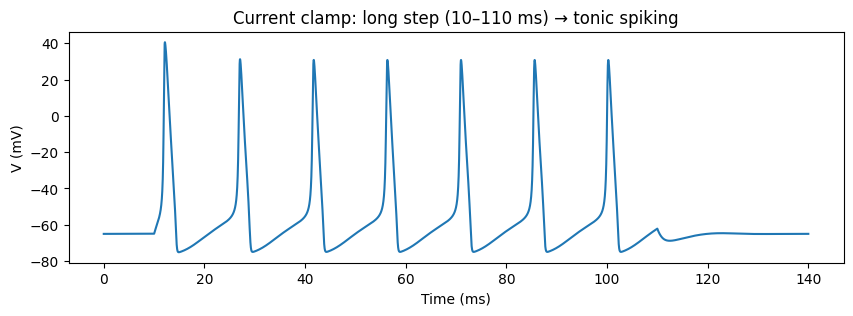


Long step metrics
Spikes in 40–110 ms:  5
Steady firing rate:    71.43 Hz
ISI mean:              14.632 ms
ISI CV:                0.000


In [103]:
# Experiment B: long step -> tonic spiking (for later comparison with F–I)
I_step = long_step_I(amp=10.0, t_on=10.0, t_off=110.0)
res_step = simulate_current_clamp(T=140.0, dt=0.01, V0=-65.0, I_of_t=I_step, p=params)

ts = res_step["t"]
Vs = res_step["V"]
Iext_s = res_step["Iext"]

plt.figure(figsize=(10, 3))
plt.plot(ts, Vs)
plt.xlabel("Time (ms)")
plt.ylabel("V (mV)")
plt.title("Current clamp: long step (10–110 ms) → tonic spiking")
plt.show()

# Long step metrics: steady firing rate + ISI stats
spk = detect_spikes(ts, Vs, thresh=0.0, refractory_ms=2.0)

# Use a steady window (discard first 30 ms after onset)
steady_spk = spk[(spk >= 40.0) & (spk <= 110.0)]
window_s = (110.0 - 40.0) / 1000.0
rate_hz = len(steady_spk) / window_s

isis = np.diff(steady_spk)
isi_mean = float(np.mean(isis)) if isis.size else np.nan
isi_cv = float(np.std(isis) / np.mean(isis)) if isis.size else np.nan

print("\nLong step metrics")
print(f"Spikes in 40–110 ms:  {len(steady_spk)}")
print(f"Steady firing rate:    {rate_hz:.2f} Hz")
print(f"ISI mean:              {isi_mean:.3f} ms")
print(f"ISI CV:                {isi_cv:.3f}")


In the experiment B: neuron has entered a stable repetitive-firing regime (a limit-cycle-like behavior) under sustained input.

I_ext shows the brief square pulse (small and short).

I_Na becomes a large inward current during the upstroke. This is exactly what we expect: sodium influx drives the spike rise.

I_K becomes a large outward current slightly later (positive). This current dominates repolarization and produces the undershoot.

### F–I curve

This section is:

1. to quantify how the steady firing rate changes as a function of constant injected DC current.

2. to identify the rheobase for sustained spiking (minimum DC current that produces nonzero steady firing) and provide a reference operating range for later comparisons.

In [104]:
# helper function
def dc_step_I(I0, t_on=50.0, t_off=450.0):
    """Return I_of_t(t): DC current I0 only between [t_on, t_off)"""
    return lambda t: (I0 if (t_on <= t < t_off) else 0.0)

In [105]:
def run_dc_trial(I0, T=500.0, dt=0.01, V0=-65.0,
                t_on=50.0, t_off=450.0, warmup_ms=50.0,
                thresh=0.0, refractory_ms=2.0, p=params):
    """
    Runs HH under current clamp with a DC step current and returns:
      - firing rate (Hz) computed on a steady window
      - full simulation result (res)
      - spike times (all detected spikes)
    """
    I_of_t = dc_step_I(I0, t_on=t_on, t_off=t_off)
    res = simulate_current_clamp(T=T, dt=dt, V0=V0, I_of_t=I_of_t, p=p)

    t = res["t"]
    V = res["V"]

    # detect spikes on the entire trace
    spk = detect_spikes(t, V, thresh=thresh, refractory_ms=refractory_ms)

    # keep spikes only in steady portion of injection
    steady_start = t_on + warmup_ms
    steady_spk = spk[(spk >= steady_start) & (spk <= t_off)]

    # duration of the steady window
    dur_s = (t_off - steady_start) / 1000.0
    fr_hz = len(steady_spk) / dur_s if dur_s > 0 else 0.0

    return fr_hz, res, spk

In [106]:
# Experiment: F–I curve
I_values = np.linspace(0.0, 20.0, 21)   # µA/cm² 
firing_rates = []

for I0 in I_values:
    fr, _, _ = run_dc_trial(I0, T=500.0, dt=0.01,
                            t_on=50.0, t_off=450.0, warmup_ms=50.0,
                            thresh=0.0, refractory_ms=2.0, p=params)
    firing_rates.append(fr)

firing_rates = np.array(firing_rates, dtype=float)

In [107]:
# Rheobase
mask = firing_rates >= 1.0
rheobase = I_values[np.argmax(mask)] if np.any(mask) else np.nan

print(f"Estimated rheobase (FR ≥ 1 Hz): {rheobase:.3f} µA/cm²")

Estimated rheobase (FR ≥ 1 Hz): 7.000 µA/cm²


F-I curve

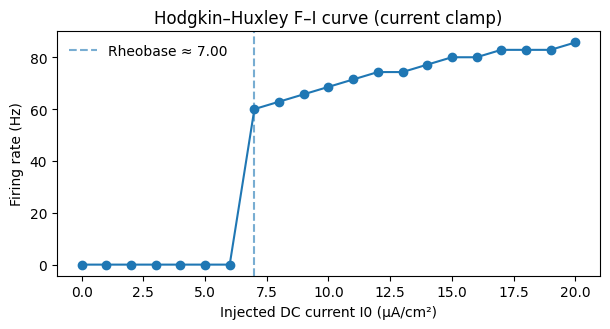

In [108]:
plt.figure(figsize=(6.2, 3.4))
plt.plot(I_values, firing_rates, marker="o")
if np.isfinite(rheobase):
    plt.axvline(rheobase, ls="--", alpha=0.6, label=f"Rheobase ≈ {rheobase:.2f}")
plt.xlabel("Injected DC current I0 (µA/cm²)")
plt.ylabel("Firing rate (Hz)")
plt.title("Hodgkin–Huxley F–I curve (current clamp)")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

Key results at Key result: rheobase≈7.00 μA/cm^2

    For 𝐼_0<7: firing rate is 0 Hz, so the neuron stays silent,
    At 𝐼_0≈7: firing suddenly appears, it means the neuron enters a repetitive spiking regime

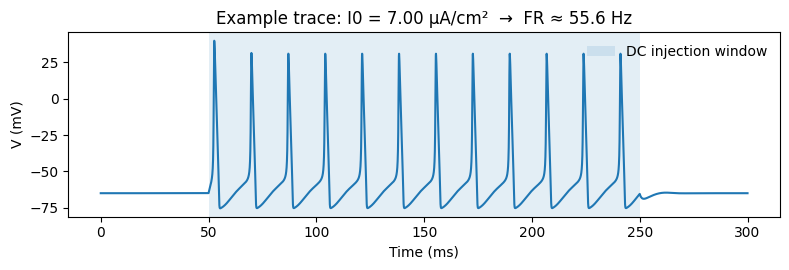

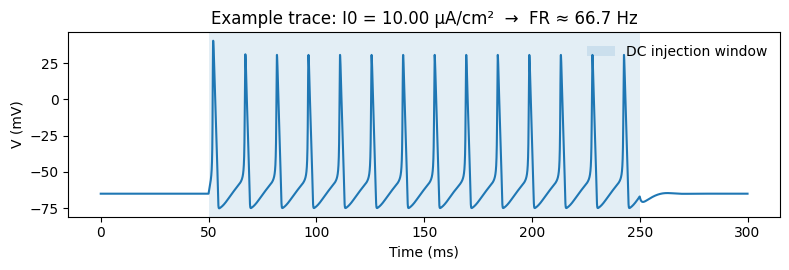

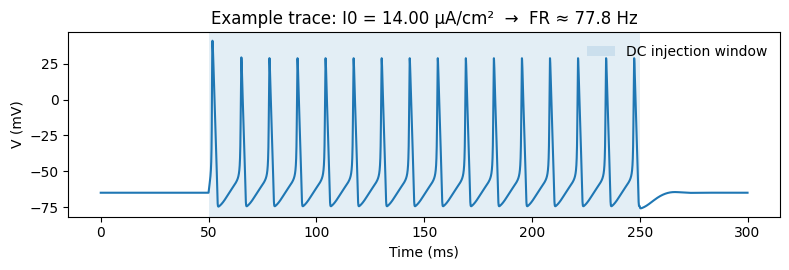

In [109]:
# voltage traces at few currents
for I0 in [rheobase if np.isfinite(rheobase) else 6.0, 10.0, 14.0]:
    fr, res, _ = run_dc_trial(I0, T=300.0, dt=0.01,
                              t_on=50.0, t_off=250.0, warmup_ms=20.0,
                              thresh=0.0, refractory_ms=2.0, p=params)

    plt.figure(figsize=(8.0, 2.8))
    plt.plot(res["t"], res["V"])
    plt.axvspan(50.0, 250.0, alpha=0.12, label="DC injection window")
    plt.xlabel("Time (ms)")
    plt.ylabel("V (mV)")
    plt.title(f"Example trace: I0 = {I0:.2f} µA/cm²  →  FR ≈ {fr:.1f} Hz")
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

Trace 1: I_0=7.00 μA/cm^2

    Plot 1: The neuron is just over threshold; its intrinsic ion-channel dynamics are able to maintain a repeating spike cycle, but only because the injected current is enough to overcome leak and recovery currents.
Trace 2: I_0=10.00 μA/cm^2

    Plot 2: Stronger drive pushes the voltage back to threshold faster after each spike.
Trace 3: I_0=14.00 μA/cm^2

    Plot 3: the limit cycle is running faster because the membrane is being held at a more depolarized operating point.

### Strength–duration curve

The aim of this section is:

1. to measure the minimum pulse amplitude required to evoke at least one spike as a function of pulse width.

2. to fit the Weiss–Lapicque relation and extract compact threshold parameters (pulse rheobase Irh and chronaxie tau_c) that summarize the strength–duration behavior.

In [110]:
# helper functions
def pulse_I(amp, t_on=10.0, width_ms=1.0):
    """Square pulse current (µA/cm²) with given amplitude and width."""
    t_off = t_on + width_ms
    return lambda t: (amp if (t_on <= t < t_off) else 0.0)

def evokes_spike_for_pulse(amp, width_ms, t_on=10.0, dt=0.01, V0=-65.0,
                          thresh=0.0, refractory_ms=2.0, p=params):
    """
    Returns True if the pulse triggers at least one spike after pulse onset.
    """
    I_of_t = pulse_I(amp, t_on=t_on, width_ms=width_ms)

    # Simulating time
    T = (t_on + width_ms + 40.0)
    res = simulate_current_clamp(T=T, dt=dt, V0=V0, I_of_t=I_of_t, p=p)

    spk = detect_spikes(res["t"], res["V"], thresh=thresh, refractory_ms=refractory_ms)
    return np.any(spk >= (t_on + 0.5))

def threshold_current_for_duration(width_ms, I_low=0.0, I_high=50.0,
                                   tol=0.02, max_iter=30, **kwargs):
    """
    Finding threshold current for a pulse duration using bisection.
    """
    lo, hi = float(I_low), float(I_high)

    for _ in range(12):
        if evokes_spike_for_pulse(hi, width_ms, **kwargs):
            break
        hi *= 1.5

    if not evokes_spike_for_pulse(hi, width_ms, **kwargs):
        return np.nan

    # Bisection search
    for _ in range(max_iter):
        mid = 0.5 * (lo + hi)
        if evokes_spike_for_pulse(mid, width_ms, **kwargs):
            hi = mid
        else:
            lo = mid
        if (hi - lo) <= tol:
            break

    return hi

In [111]:
# Compute I_th
durations = np.array([0.2, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0], dtype=float)

I_th = []
for d in durations:
    Ith = threshold_current_for_duration(
        width_ms=d,
        I_low=0.0,
        I_high=50.0,
        tol=0.02,
        dt=0.01,
        t_on=10.0,
        V0=-65.0,
        thresh=0.0,
        refractory_ms=2.0,
        p=params
    )
    I_th.append(Ith)

I_th = np.array(I_th, dtype=float)

Weiss–Lapicque linearization 

I_th(d) = I_rh * (1 + tau_ch / d) >>> I_th = a + b*(1/d), where a = I_rh and b = I_rh*tau_ch

In [112]:
x = 1.0 / durations
y = I_th

valid = np.isfinite(y)
I_rh = np.nan
tau_ch = np.nan
coef = None

if np.sum(valid) >= 2:
    X = np.vstack([np.ones_like(x[valid]), x[valid]]).T
    coef, _, _, _ = np.linalg.lstsq(X, y[valid], rcond=None)
    I_rh, b = float(coef[0]), float(coef[1])
    tau_ch = b / max(I_rh, 1e-12)

print("Strength–duration results")
for d, Ith in zip(durations, I_th):
    print(f"d = {d:>5.1f} ms  >>>  I_th = {Ith:>7.3f} µA/cm²")

if np.isfinite(I_rh) and np.isfinite(tau_ch):
    print(f"\nWeiss–Lapicque fit estimates:")
    print(f"Rheobase I_rh  ≈ {I_rh:.3f} µA/cm²")
    print(f"Chronaxie τ_ch ≈ {tau_ch:.3f} ms")
else:
    print("\nWeiss–Lapicque fit: not enough valid points.")

Strength–duration results
d =   0.2 ms  >>>  I_th =  32.629 µA/cm²
d =   0.5 ms  >>>  I_th =  13.269 µA/cm²
d =   1.0 ms  >>>  I_th =   6.921 µA/cm²
d =   2.0 ms  >>>  I_th =   3.857 µA/cm²
d =   5.0 ms  >>>  I_th =   2.356 µA/cm²
d =  10.0 ms  >>>  I_th =   2.246 µA/cm²
d =  20.0 ms  >>>  I_th =   2.246 µA/cm²

Weiss–Lapicque fit estimates:
Rheobase I_rh  ≈ 1.202 µA/cm²
Chronaxie τ_ch ≈ 5.182 ms


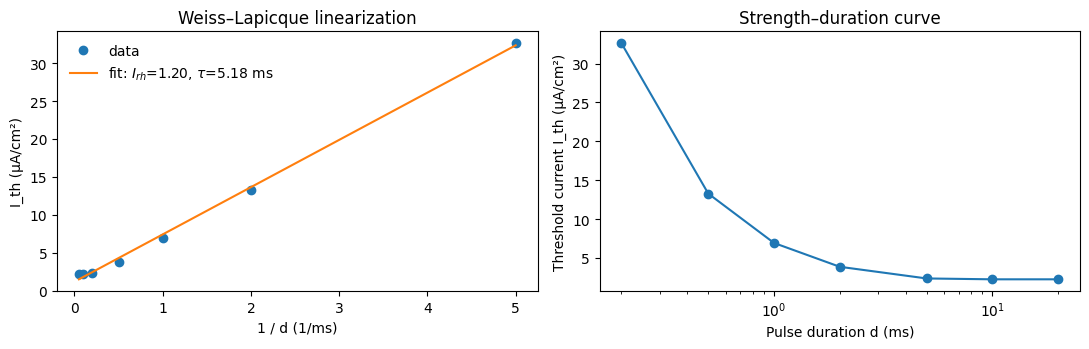

In [113]:
# Plots
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

# Strength–duration curve
axes[1].plot(durations, I_th, marker="o")
axes[1].set_xscale("log")
axes[1].set_xlabel("Pulse duration d (ms)")
axes[1].set_ylabel("Threshold current I_th (µA/cm²)")
axes[1].set_title("Strength–duration curve")

# Weiss–Lapicque linearization plot
axes[0].plot(x, y, "o", label="data")
if coef is not None and np.isfinite(I_rh) and np.isfinite(tau_ch):
    xx = np.linspace(np.min(x[valid]), np.max(x[valid]), 200)
    yy = coef[0] + coef[1] * xx
    axes[0].plot(xx, yy, "-", label=rf"fit: $I_{{rh}}$={I_rh:.2f}, $\tau$={tau_ch:.2f} ms")
axes[0].set_xlabel("1 / d (1/ms)")
axes[0].set_ylabel("I_th (µA/cm²)")
axes[0].set_title("Weiss–Lapicque linearization")
axes[0].legend(frameon=False)

plt.tight_layout()
plt.show()


Interpretation of Weiss-Lapicque linearizarion:
𝐼_rh≈1.20 μA/cm^2

    This is the rheobase for this pulse-threshold experiment: the minimum current needed if the pulse is very long.

𝜏≈5.18 ms
    
    In this model, 𝜏 is the chronaxie: the pulse duration where the threshold current is twice rheobase
    
Interpretation of Strength-duration curve:

    For very small 𝑑, 𝐼_th is huge (~30+ µA/cm²): you’re forcing the membrane fast.

    As 𝑑 increases, 𝐼_th drops quickly.

    For large 𝑑, 𝐼_th flattens near a constant ≈ rheobase (~1–2 µA/cm²).

That flattening is the key: there’s a minimum current scale, and longer pulses can’t go below it.

### Voltage-clamp validation of gating kinetics

This section is for:

1. to validate that the implemented HH gating dynamics reproduce the expected steady-state curves and time constants (m_inf(V), h_inf(V), n_inf(V) and tau_m(V), tau_h(V), tau_n(V)) under controlled voltage steps,

2. to extract x_inf and tau from simulated clamp relaxations and compare them to the analytic HH expressions as a consistency check for both the model and the estimation pipeline.

In [114]:
def V_step_protocol(t, V_hold=-65.0, V_test=0.0, t_on=10.0, t_off=40.0):
    return V_test if (t_on <= t < t_off) else V_hold

def run_gate_relaxation_clamp(V_test, V_hold=-65.0, t_on=10.0, t_off=40.0, T=60.0, dt=0.01):
    Vcmd = lambda t: V_step_protocol(t, V_hold=V_hold, V_test=V_test, t_on=t_on, t_off=t_off)
    return simulate_voltage_clamp(T=T, dt=dt, V_hold=V_hold, Vcmd_of_t=Vcmd, p=params)


In [115]:
def estimate_tau_63(t, x, t_on, t_off, tail_ms=5.0):
    t = np.asarray(t); x = np.asarray(x)
    mask = (t >= t_on) & (t < t_off)
    tseg = t[mask]
    xseg = x[mask]
    if len(tseg) < 10:
        return np.nan, np.nan

    x0 = float(xseg[0])
    tail_mask = tseg >= (t_off - tail_ms)
    x_inf = float(np.mean(xseg[tail_mask]))

    target = x0 + 0.632 * (x_inf - x0)
    if x_inf >= x0:
        idx = np.where(xseg >= target)[0]
    else:
        idx = np.where(xseg <= target)[0]

    if idx.size == 0:
        return x_inf, np.nan

    tau_est = float(tseg[idx[0]] - tseg[0])
    return x_inf, tau_est


In [116]:
V_tests = np.array([-80, -60, -40, -20, 0, 20, 40], dtype=float)

m_inf_est, h_inf_est, n_inf_est = [], [], []
tau_m_est, tau_h_est, tau_n_est = [], [], []

t_on = 10.0  #

for Vt in V_tests:
    vc = run_gate_relaxation_clamp(Vt, V_hold=-65.0, t_on=t_on, t_off=40.0, T=60.0, dt=0.01)

    t = vc["t"]
    m = vc["m"]; h = vc["h"]; n = vc["n"]

    mi, tm = estimate_tau_63(t, m, t_on, t_off=40.0)
    hi, th = estimate_tau_63(t, h, t_on, t_off=40.0)
    ni, tn = estimate_tau_63(t, n, t_on, t_off=40.0)

    m_inf_est.append(mi); tau_m_est.append(tm)
    h_inf_est.append(hi); tau_h_est.append(th)
    n_inf_est.append(ni); tau_n_est.append(tn)

m_inf_est = np.array(m_inf_est); h_inf_est = np.array(h_inf_est); n_inf_est = np.array(n_inf_est)
tau_m_est = np.array(tau_m_est); tau_h_est = np.array(tau_h_est); tau_n_est = np.array(tau_n_est)

# analytic curves 
x_inf_a, tau_a = gate_inf_tau(V_tests) 

Analytic vs Clamp-estimated plot

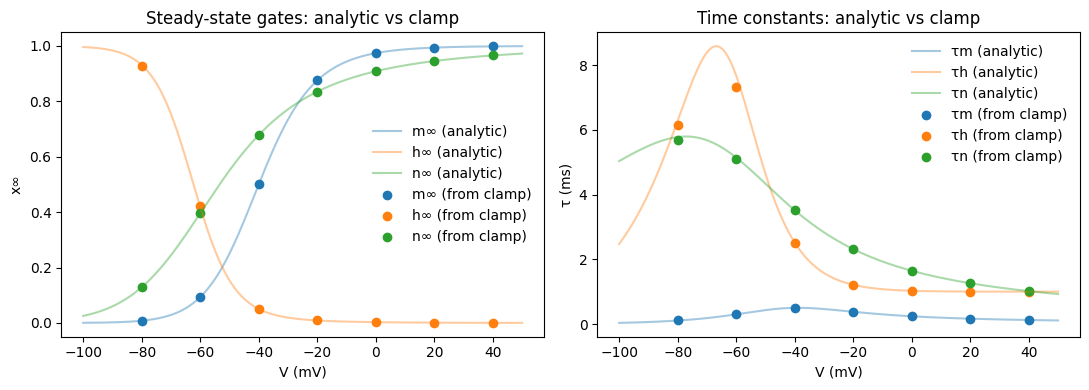

In [117]:
Vs = np.linspace(-100, 50, 400)

x_inf, tau_x = gate_inf_tau(Vs)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(Vs, x_inf["m"], alpha=0.4, label="m∞ (analytic)")
ax[0].plot(Vs, x_inf["h"], alpha=0.4, label="h∞ (analytic)")
ax[0].plot(Vs, x_inf["n"], alpha=0.4, label="n∞ (analytic)")
ax[0].scatter(V_tests, m_inf_est, label="m∞ (from clamp)")
ax[0].scatter(V_tests, h_inf_est, label="h∞ (from clamp)")
ax[0].scatter(V_tests, n_inf_est, label="n∞ (from clamp)")
ax[0].set_xlabel("V (mV)")
ax[0].set_ylabel("x∞")
ax[0].set_title("Steady-state gates: analytic vs clamp")
ax[0].legend(frameon=False)

ax[1].plot(Vs, tau_x["m"], alpha=0.4, label="τm (analytic)")
ax[1].plot(Vs, tau_x["h"], alpha=0.4, label="τh (analytic)")
ax[1].plot(Vs, tau_x["n"], alpha=0.4, label="τn (analytic)")
ax[1].scatter(V_tests, tau_m_est, label="τm (from clamp)")
ax[1].scatter(V_tests, tau_h_est, label="τh (from clamp)")
ax[1].scatter(V_tests, tau_n_est, label="τn (from clamp)")
ax[1].set_xlabel("V (mV)")
ax[1].set_ylabel("τ (ms)")
ax[1].set_title("Time constants: analytic vs clamp")
ax[1].legend(frameon=False)

plt.tight_layout()
plt.show()


Interpretation of Steady-state gates:

    The clamp-estimated points closely match the analytic HH curves: m∞ increases with depolarization, h∞ decreases (Na inactivation), and n∞ increases more gradually (K activation). Voltage-clamp extraction is recovering the expected steady-state voltage dependence of the HH gates.

Interpretation of Time constants:

    τm is small across voltages (fast Na activation), while τh and τn are slower (inactivation and K activation), matching the HH timescale separation.
    τh shows a clear peak around ~ -70 to -60 mV and then decreases with depolarization; τn is a few ms at negative V and decreases as V increases — consistent with classic HH kinetics and confirming the clamp-based τ estimates are now reasonable.


### dt sensitivity check

This section is:

1. to verify that the numerical solution is stable and that spike shape/timing are not artifacts of the chosen time step dt.

2. to quantify discretization error and justify the selected dt as an accuracy–cost tradeoff for all experiments.

In [118]:
def I_test(t):
    # step causing spiking 
    return step_current(t, amp=10.0, t_on=10.0, t_off=40.0)

In [119]:
T = 60.0
V0 = -65.0
dt_list = [0.02, 0.01, 0.005] 

runs = {}
for dt in dt_list:
    runs[dt] = simulate_current_clamp(T=T, dt=dt, V0=V0, I_of_t=I_test, p=params)


V(t) plot

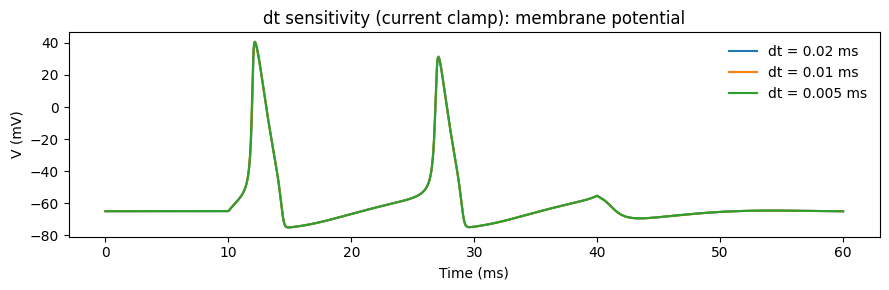

In [120]:
plt.figure(figsize=(9, 3))
for dt in dt_list:
    plt.plot(runs[dt]["t"], runs[dt]["V"], label=f"dt = {dt} ms")
plt.xlabel("Time (ms)")
plt.ylabel("V (mV)")
plt.title("dt sensitivity (current clamp): membrane potential")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


Interpretation of dt sensitivity:

    The voltage traces for dt=0.02, 0.01, 0.005 ms overlap, meaning the numerical solution is stable and the spike shape/timing isn’t an artifact of the time step.

So dt≈0.02 ms is already small enough for accurate HH spiking; decreasing dt further gives negligible change.

In [121]:
def interp_to(t_new, t_old, y_old):
    return np.interp(t_new, t_old, y_old)

dt_ref = min(dt_list)
t_ref = runs[dt_ref]["t"]
V_ref = runs[dt_ref]["V"]

print("dt sensitivity metrics (vs finest dt)")
for dt in dt_list:
    V_dt = interp_to(t_ref, runs[dt]["t"], runs[dt]["V"])
    err = V_dt - V_ref
    rmse = np.sqrt(np.mean(err**2))
    max_abs = np.max(np.abs(err))
    print(f"dt={dt:>6} ms  RMSE={rmse:8.4f} mV   max|err|={max_abs:8.4f} mV")


dt sensitivity metrics (vs finest dt)
dt=  0.02 ms  RMSE=  0.4875 mV   max|err|=  7.7367 mV
dt=  0.01 ms  RMSE=  0.1645 mV   max|err|=  2.6125 mV
dt= 0.005 ms  RMSE=  0.0000 mV   max|err|=  0.0000 mV


In [122]:
def first_spike_time(res, thresh=0.0, refractory_ms=2.0):
    spk = detect_spikes(res["t"], res["V"], thresh=thresh, refractory_ms=refractory_ms)
    return float(spk[0]) if spk.size else np.nan

t_ref_spk = first_spike_time(runs[dt_ref])

print("\nFirst-spike timing")
print(f"Reference dt={dt_ref} ms: t_spike = {t_ref_spk:.4f} ms")
for dt in dt_list:
    t_spk = first_spike_time(runs[dt])
    diff = t_spk - t_ref_spk if np.isfinite(t_spk) and np.isfinite(t_ref_spk) else np.nan
    print(f"dt={dt:>6} ms: t_spike = {t_spk:.4f} ms   Δt = {diff:.4f} ms")



First-spike timing
Reference dt=0.005 ms: t_spike = 11.9097 ms
dt=  0.02 ms: t_spike = 11.9344 ms   Δt = 0.0246 ms
dt=  0.01 ms: t_spike = 11.9180 ms   Δt = 0.0083 ms
dt= 0.005 ms: t_spike = 11.9097 ms   Δt = 0.0000 ms
